# 03. Preprocessing and features (Consistency)

**Goal.** Decide how the raw Consistency columns become model inputs and how the training labels are built, using **validation results only**.
The outer test groups are not touched.

Decisions tested on the same 20 combinations as notebook 02:

1. **Which features, in which form?** The proposal's features and simpler or richer subsets (see the variants table).
2. **Which training labels?** Rated records only, plus labels for unrated records from a small model fitted on the rated ones, with or
   without synthetic records; and the weight of those propagated labels (1 or 0.3).
3. **How to treat students with no activity?** As ordinary rows, or by a **rule**: inactive records are left out of training and predicted as 0 (undefined consistency is not 'worst consistency').

**Leak-proof by construction.** The imputer, the scaler and the label model are fitted on the training rows of each combination only
(`../ml_lib/features.py`). Missing values are imputed with the training median and flagged.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Consistency (744, 25)


In [2]:
splits = pd.read_csv(F.splits)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
print(len(combos), "combinations;", len(GOLD), "rated records;", len(VARIANTS), "feature variants")
pd.DataFrame({"inputs": {n: ", ".join(f"{c}{'' if tf == 'raw' else ' (' + tf + ')'}" for c, tf in spec) for n, spec in VARIANTS.items()}})

20 combinations; 20 rated records; 8 feature variants


,inputs
proposal 4,"C_AWR, C_DC (one_minus), C_LI_norm (one_minus)..."
proposal 4 + no-activity flag,"C_AWR, C_DC (one_minus), C_LI_norm (one_minus)..."
proposal 4 + bimodal flag,"C_AWR, C_DC (one_minus), C_LI_norm (one_minus)..."
proposal 4 + first active day,"C_AWR, C_DC (one_minus), C_LI_norm (one_minus)..."
3 features (no CV),"C_AWR, C_DC (one_minus), C_LI_norm (one_minus)"
AWR + 1-DC,"C_AWR, C_DC (one_minus)"
AWR only,C_AWR
commits (log) + AWR,"E_CC (log), C_AWR"


## 1. Proof that nothing leaks

For one combination, the imputer and scaler inside the model learn only from the training rows. We change every validation and test feature
drastically and check the training data and its labels do not move.

In [3]:
test, val, roles = combos[0]
spec = VARIANTS[list(VARIANTS)[0]]
featurize = lambda f: design(f, spec)  # noqa: E731
X, y, w, ids = training_set(d, roles, featurize, LABEL, PROPOSAL, "rated + propagated (real)")
held = roles[roles.role.isin(["val", "test"])].record_id
d2 = d.copy()
for col in {c for c, _ in spec} | {c for c, _ in PROPOSAL}:
    d2.loc[held, col] = 9999
X2, y2, w2, ids2 = training_set(d2, roles, lambda f: design(f, spec), LABEL, PROPOSAL, "rated + propagated (real)")
assert np.array_equal(X, X2, equal_nan=True) and np.allclose(y, y2), "training data changed when validation or test rows changed"
m = fit_linear(linear_model(1.0), X, y, w)
assert np.allclose(m.named_steps["standardscaler"].mean_, np.nanmean(m.named_steps["simpleimputer"].transform(X), axis=0)), "scaler not fitted on training rows"
print("OK: training data, propagated labels and scaler depend only on the training rows")
print("training rows in this combination:", len(ids), "| rated:", int((w == 1).sum()))

OK: training data, propagated labels and scaler depend only on the training rows
training rows in this combination: 45 | rated: 45


## 2. Label construction

For unrated rows the label comes from a Ridge model fitted on the rated rows of the training groups. How good is it on held-out rated rows?
That is the quality ceiling of every propagated label.

In [4]:
rows = []
for test, val, roles in combos:
    t = d.loc[roles[roles.role == "train"].record_id]
    prop = Propagator(t[(t.source == "real") & (t.label_source == "rater")], PROPOSAL, LABEL)
    v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
    rows += [(test, val, y, p) for y, p in zip(v[LABEL], prop.predict(v))]
lab = pd.DataFrame(rows, columns=["outer_test", "inner_val", "y", "pred"])
m = metrics(lab.y, lab.pred)
print(f"label model on held-out rated records: MAE {m['MAE']:.3f}, RMSE {m['RMSE']:.3f}, Pearson {m['pearson']:.3f}, n={m['n']}")

label model on held-out rated records: MAE 0.067, RMSE 0.093, Pearson 0.910, n=80


## 3. The experiment

For each variant, label source, weight and `alpha` in {0.1, 1, 10} (varied only to check the conclusion does not depend on it; it is tuned
in notebook 04): train Ridge on each combination's training rows, predict the rated records of the validation group, pool over the 20
combinations.

In [5]:
WEIGHTS, ALPHA_GRID = [1.0, 0.3], [0.1, 1.0, 10.0]
RULES = [False, True] if ZERO_RULE_OK else [False]
records = []
for variant, spec in VARIANTS.items():
    featurize = lambda f, spec=spec: design(f, spec)  # noqa: E731
    for source in LABEL_SOURCES:
        for weight in (WEIGHTS if source != "rated only" else [1.0]):
            for rule in RULES:
                for test, val, roles in combos:
                    X, y, w, ids = training_set(d, roles, featurize, LABEL, PROPOSAL, source, weight)
                    if rule:
                        keep = d.loc[ids, ACT].to_numpy() > 0
                        X, y, w = X[keep], y[keep], w[keep]
                    v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
                    Xv = featurize(v)
                    for alpha in ALPHA_GRID:
                        p = np.clip(fit_linear(linear_model(alpha), X, y, w).predict(Xv), 0, 1)
                        if rule:
                            p = np.where(v[ACT].to_numpy() == 0, 0.0, p)
                        records += [(variant, source, weight, rule, alpha, test, val, r, g, yy, pp, a)
                                    for r, g, yy, pp, a in zip(v.record_id, v.group, v[LABEL], p, v[ACT])]
res = pd.DataFrame(records, columns=["variant", "label_source", "weight", "zero_rule", "alpha", "outer_test", "inner_val", "record_id", "group", "y", "pred", "activity"])
res["abs_err"] = (res.pred - res.y).abs()
res.to_csv(F.results / "preprocessing_validation_predictions.csv", index=False)
print(len(res), "predictions;", res.groupby(["variant", "label_source", "weight", "zero_rule"]).ngroups, "configurations")

19200 predictions; 80 configurations


## 4. Results

In [6]:
cfg = ["variant", "label_source", "weight", "zero_rule"]
table = res.groupby(cfg + ["alpha"]).abs_err.mean().groupby(cfg).mean().rename("MAE (mean over alpha)").reset_index()
act = res[res.activity > 0].groupby(cfg).abs_err.mean().rename("MAE active only").reset_index()
table = table.merge(act, on=cfg).sort_values("MAE (mean over alpha)").reset_index(drop=True)
table.round(3).head(15)

,variant,label_source,weight,zero_rule,MAE (mean over alpha),MAE active only
0,proposal 4 + first active day,rated + propagated (real),0.3,True,0.065,0.076
1,proposal 4 + first active day,rated + propagated (real),0.3,False,0.065,0.076
2,proposal 4 + first active day,rated + propagated (real + synthetic),0.3,True,0.065,0.077
3,proposal 4 + first active day,rated + propagated (real),1.0,True,0.065,0.077
4,proposal 4 + first active day,rated + propagated (real + synthetic),0.3,False,0.066,0.077
5,proposal 4 + first active day,rated + propagated (real),1.0,False,0.066,0.077
6,proposal 4 + first active day,rated + propagated (real + synthetic),1.0,True,0.066,0.077
7,proposal 4 + first active day,rated + propagated (real + synthetic),1.0,False,0.066,0.078
8,proposal 4 + bimodal flag,rated + propagated (real),1.0,True,0.066,0.078
9,proposal 4,rated + propagated (real),1.0,True,0.066,0.078


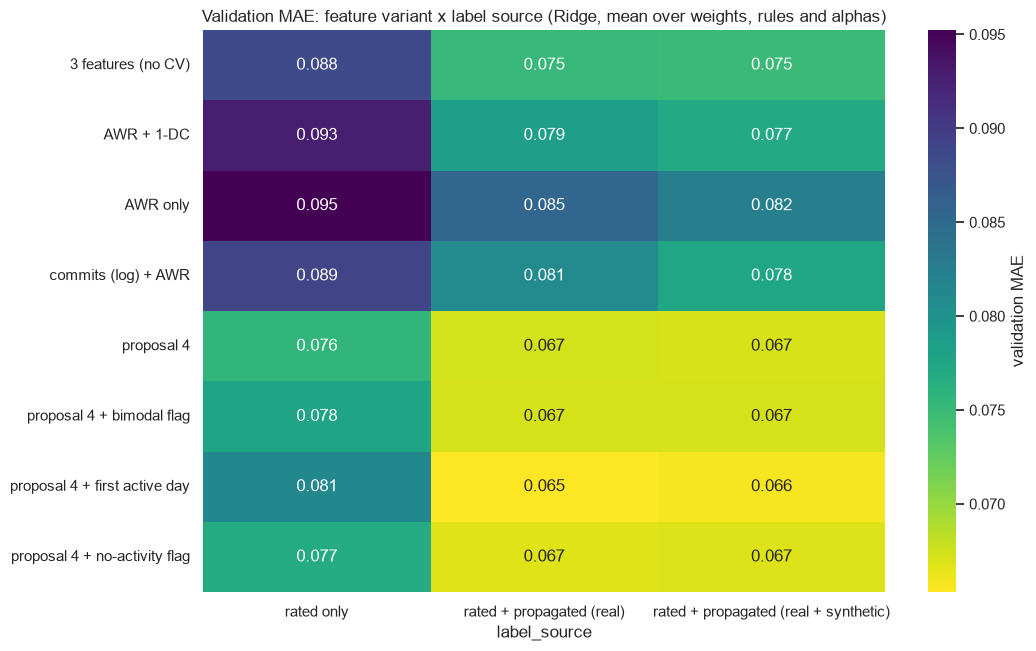

zero_rule,False,True
variant,,
3 features (no CV),0.077,0.078
AWR + 1-DC,0.080,0.081
AWR only,0.086,0.086
commits (log) + AWR,0.080,0.083
proposal 4,0.069,0.069
proposal 4 + bimodal flag,0.069,0.070
proposal 4 + first active day,0.068,0.069
proposal 4 + no-activity flag,0.069,0.069


In [7]:
pivot = res.groupby(["variant", "label_source"]).abs_err.mean().unstack("label_source")[LABEL_SOURCES]
fig, ax = plt.subplots(figsize=(11, 0.6 * len(VARIANTS) + 2.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "validation MAE"})
ax.set(title="Validation MAE: feature variant x label source (Ridge, mean over weights, rules and alphas)", ylabel="")
plt.show()
rule_effect = res.groupby(["variant", "zero_rule"]).abs_err.mean().unstack("zero_rule") if ZERO_RULE_OK else None
rule_effect.round(3) if ZERO_RULE_OK else res.groupby(["variant", "weight"]).abs_err.mean().unstack("weight").round(3)

## 5. Choosing, by a rule written before looking

In [8]:
def simplicity(row):
    return (len(VARIANTS[row.variant]), LABEL_SOURCES.index(row.label_source), row.weight != 1.0, bool(row.zero_rule))

best = table.iloc[0]
sel = res[(res.variant == best.variant) & (res.label_source == best.label_source) & (res.weight == best.weight) & (res.zero_rule == best.zero_rule)]
rng = np.random.default_rng(SEED)
groups = sel.group.unique()
boot = [np.mean(np.concatenate([sel[sel.group == g].abs_err.to_numpy() for g in rng.choice(groups, len(groups), replace=True)])) for _ in range(1000)]
se = float(np.std(boot))
near = table[table["MAE (mean over alpha)"] <= best["MAE (mean over alpha)"] + se].copy()
near["rank"] = near.apply(simplicity, axis=1)
choice = near.sort_values("rank").iloc[0]
print(f"best: {best.variant} | {best.label_source} | weight {best.weight} | zero rule {best.zero_rule} | MAE {best['MAE (mean over alpha)']:.3f} (SE {se:.3f})")
print(f"settings within one SE: {len(near)}")
print(f"chosen (simplest within one SE): {choice.variant} | {choice.label_source} | weight {choice.weight} | zero rule {choice.zero_rule} | MAE {choice['MAE (mean over alpha)']:.3f}")
near.drop(columns="rank").round(3).head(12)

best: proposal 4 + first active day | rated + propagated (real) | weight 0.3 | zero rule True | MAE 0.065 (SE 0.010)
settings within one SE: 40
chosen (simplest within one SE): 3 features (no CV) | rated + propagated (real) | weight 1.0 | zero rule False | MAE 0.075


,variant,label_source,weight,zero_rule,MAE (mean over alpha),MAE active only
0,proposal 4 + first active day,rated + propagated (real),0.3,True,0.065,0.076
1,proposal 4 + first active day,rated + propagated (real),0.3,False,0.065,0.076
2,proposal 4 + first active day,rated + propagated (real + synthetic),0.3,True,0.065,0.077
3,proposal 4 + first active day,rated + propagated (real),1.0,True,0.065,0.077
4,proposal 4 + first active day,rated + propagated (real + synthetic),0.3,False,0.066,0.077
5,proposal 4 + first active day,rated + propagated (real),1.0,False,0.066,0.077
6,proposal 4 + first active day,rated + propagated (real + synthetic),1.0,True,0.066,0.077
7,proposal 4 + first active day,rated + propagated (real + synthetic),1.0,False,0.066,0.078
8,proposal 4 + bimodal flag,rated + propagated (real),1.0,True,0.066,0.078
9,proposal 4,rated + propagated (real),1.0,True,0.066,0.078


In [9]:
decision = {"variant": choice.variant, "label_source": choice.label_source, "pseudo_weight": float(choice.weight), "zero_rule": bool(choice.zero_rule),
            "features": [c for c, _ in VARIANTS[choice.variant]], "validation_MAE": round(float(choice["MAE (mean over alpha)"]), 4),
            "standard_error": round(se, 4), "rule": "lowest validation MAE, then simplest within one bootstrap SE"}
(F.results / "preprocessing_choice.json").write_text(json.dumps(decision, indent=2))
log_run(F, "03_preprocessing_and_features", choice.variant, f"chosen; {choice.label_source}; weight {choice.weight}; zero rule {choice.zero_rule}; validation",
        {"MAE": decision["validation_MAE"], "SE": decision["standard_error"]})
print(json.dumps(decision, indent=2))

{
  "variant": "3 features (no CV)",
  "label_source": "rated + propagated (real)",
  "pseudo_weight": 1.0,
  "zero_rule": false,
  "features": [
    "C_AWR",
    "C_DC",
    "C_LI_norm"
  ],
  "validation_MAE": 0.0749,
  "standard_error": 0.0102,
  "rule": "lowest validation MAE, then simplest within one bootstrap SE"
}


## 6. Reading the results

Validation MAE, pooled over the 20 combinations, Ridge; baselines from notebook 02 were Ridge on the four proposal features 0.066 and the
mean 0.195.

| Question | Answer from the tables above |
|---|---|
| Best variant | The four proposal features plus the first active day, propagated real labels, weight 0.3: **0.065** (standard error 0.010) |
| Are all four proposal features needed? | **Mostly.** Four features 0.069; dropping `CV` 0.077-0.078; `AWR` + `1 - DC` 0.080; `AWR` alone 0.086. Each feature removed costs 0.008-0.017. |
| Do extra features help (no-activity flag, bimodal flag, first active day)? | No: 0.068-0.070, within 0.001 of the four proposal features. |
| Is commit volume a substitute? | No. Commits (log) + `AWR` is 0.080-0.083, worse than the proposal's four (0.069). |
| Does treating inactive students by a **rule** (train on active students, predict 0 for inactive) matter? | **No.** 0.069 either way. Their features already sit at the worst values, so a linear model reaches 0 for them. |
| Do propagated labels help? | **Yes, for this factor.** Ridge chose "rated + propagated (real)" in all of the top settings. The label model is good here (held-out MAE 0.067, correlation 0.91), unlike Task Complexity. |
| Do synthetic records help? | No (0.001 worse). |
| Does the weight on propagated labels matter? | Barely (0.3 vs 1.0 differ by 0.001). |

**What the rule chose.** All settings with four features lie within one standard error (0.010) of the best, as does the three-feature set without
`CV`. The rule picks the simplest: **`AWR`, `1 - DC`, `1 - LI`** with propagated real labels, MAE 0.075. Note that this is 0.009 worse than
the proposal's four features (0.066): a difference smaller than the noise, but a reminder that the rule trades accuracy for simplicity.
Notebook 04 therefore tunes **both** the proposal's four features and this three-feature set.

**What it means.**
- Unlike Effort, every proposal feature carries information; the model is a genuine multi-feature one, not a counter in disguise.
- The strong, consistent signal is why propagated labels help: they are good enough to be learned from.
- Notebook 04 asks whether non-linear models find structure in the discrete, bounded features that Ridge cannot.

Next: **04. Hyperparameter tuning**.